In [21]:
print("Welcome to my cat vs dog CNN project")

Welcome to my cat vs dog CNN project


In [29]:

import os

print(os.listdir("/content"))


['.config', 'kaggle.json', '.ipynb_checkpoints', 'CatDog.zip (1).zip', 'CatDog.zip.zip', 'sample_data']


In [31]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving CatDog_zip.zip to CatDog_zip.zip
Uploaded files: ['CatDog_zip.zip']


In [32]:

import os
import zipfile

zip_name = list(uploaded.keys())[0]
zip_path = os.path.join("/content", zip_name)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully!")
print("Files in Colab:", os.listdir("/content"))


Dataset extracted successfully!
Files in Colab: ['.config', 'CatDog_zip.zip', 'kaggle.json', '.ipynb_checkpoints', 'CatDog', 'CatDog.zip (1).zip', 'CatDog.zip.zip', 'sample_data']


In [37]:
import os

print(os.listdir("/content"))

['.config', 'CatDog_zip.zip', 'kaggle.json', '.ipynb_checkpoints', 'CatDog', 'CatDog.zip (1).zip', 'CatDog.zip.zip', 'sample_data']


In [38]:
import os

print("Main folders:", os.listdir("/content/CatDog"))

Main folders: ['test', 'catvdog', 'train']


In [39]:
import os

for root, dirs, files in os.walk("/content/CatDog"):
    print(root, "->", len(files), "files")

/content/CatDog -> 0 files
/content/CatDog/test -> 0 files
/content/CatDog/test/cats -> 15 files
/content/CatDog/test/dogs -> 15 files
/content/CatDog/catvdog -> 0 files
/content/CatDog/catvdog/test -> 0 files
/content/CatDog/catvdog/test/cats -> 16 files
/content/CatDog/catvdog/test/dogs -> 15 files
/content/CatDog/catvdog/train -> 0 files
/content/CatDog/catvdog/train/cats -> 15 files
/content/CatDog/catvdog/train/dogs -> 16 files
/content/CatDog/train -> 0 files
/content/CatDog/train/cats -> 15 files
/content/CatDog/train/dogs -> 15 files


In [41]:
import tensorflow as tf

train_dir = "/content/CatDog/train"
test_dir = "/content/CatDog/test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(128, 128),
    batch_size=5,
    label_mode="binary"
)

print("Classes:", train_ds.class_names)
print("Dataset loaded successfully!")

Found 30 files belonging to 2 classes.
Found 30 files belonging to 2 classes.
Classes: ['cats', 'dogs']
Dataset loaded successfully!


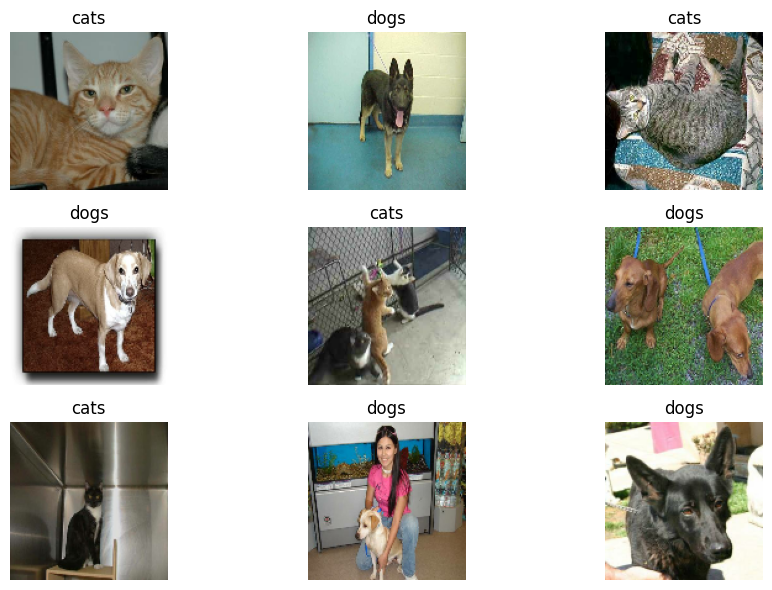

In [42]:
import matplotlib.pyplot as plt

class_names = train_ds.class_names

plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i][0])
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [43]:
from tensorflow.keras import layers

normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

print("Image normalization completed!")

Image normalization completed!


In [44]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation="relu",
           input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [46]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5
)

Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.4667 - loss: 0.7079 - val_accuracy: 0.5000 - val_loss: 0.7566
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.6667 - loss: 0.7638 - val_accuracy: 0.5000 - val_loss: 2.2364
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 1.7337 - val_accuracy: 0.5000 - val_loss: 0.8460
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6000 - loss: 1.1514 - val_accuracy: 0.5000 - val_loss: 0.9190
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6000 - loss: 1.0332 - val_accuracy: 0.5000 - val_loss: 0.6893


In [47]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step - accuracy: 0.5000 - loss: 0.6893
Test Loss: 0.6893284916877747
Test Accuracy: 50.0 %


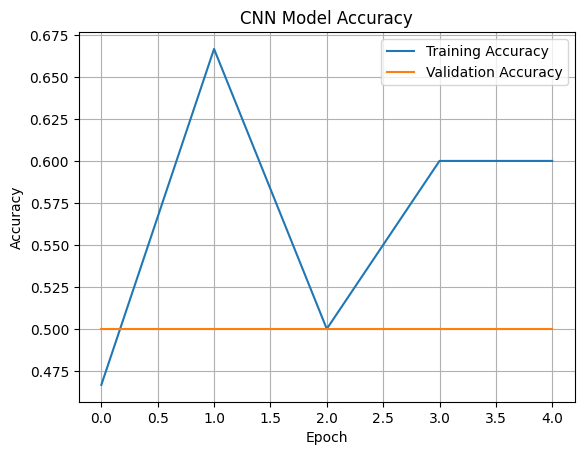

In [48]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [49]:
from google.colab import files

uploaded = files.upload()

Saving cat.99.jpg to cat.99.jpg


AttributeError: '_MapDataset' object has no attribute 'class_names'

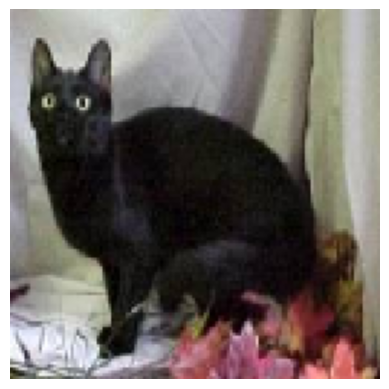

In [50]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Get the uploaded image filename
image_path = list(uploaded.keys())[0]

# Load and resize the image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

# Convert image to array and normalize
img_array = tf.keras.utils.img_to_array(img) / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array, verbose=0)[0][0]

# Display image and prediction
plt.imshow(img)
plt.axis("off")

if prediction >= 0.5:
    print(f"Prediction: {train_ds.class_names[1]}")
    print(f"Confidence: {prediction * 100:.2f}%")
else:
    print(f"Prediction: {train_ds.class_names[0]}")
    print(f"Confidence: {(1 - prediction) * 100:.2f}%")

plt.show()

In [51]:
class_names = ["cats", "dogs"]
print(class_names)

['cats', 'dogs']


Prediction: cats
Confidence: 65.57%


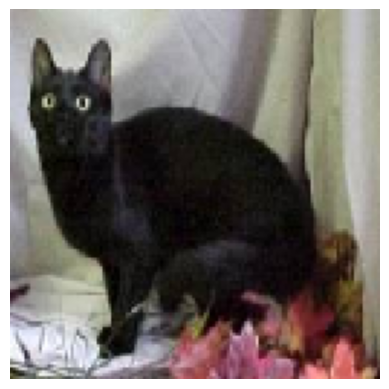

In [52]:
plt.imshow(img)
plt.axis("off")

if prediction >= 0.5:
    print("Prediction:", class_names[1])
    print(f"Confidence: {prediction * 100:.2f}%")
else:
    print("Prediction:", class_names[0])
    print(f"Confidence: {(1 - prediction) * 100:.2f}%")

plt.show()